<a href="https://colab.research.google.com/github/xxbeeboxx/React-Jobs/blob/main/AI_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
## Environment and agent
import random
from collections import deque
import numpy as np

# when my agent moves it has a probability of slipping in a specific direction, these are the respective slipping directions
SLIP = {"LEFT": "UP", "RIGHT": "DOWN", "UP": "RIGHT", "DOWN": "LEFT"}
# the step in each direction
MOVES = {"DOWN": (1, 0), "UP": (-1, 0), "RIGHT": (0, 1), "LEFT": (0, -1)}

class FrozenTreasureWorld:
    """
    Symbols:
        S : Start
        G : Gold
        H : Hole
        . : Safe cell
        B : Breeze percept
    """

    # initialising p (chance the move works), the agent's position, and whether it has the gold
    def __init__(self, size=20, hole_prob=0.05, p=0.8, seed=None):
        self.size = size
        self.hole_prob = hole_prob
        self.p = p

        if seed is not None:
            random.seed(seed)
            np.random.seed(seed)

        self.grid = None
        self.gold_pos = None
        self.start_pos = (0, 0)

        self.generate_world()
        self.pos = self.start_pos
        self.has_gold = False


    # --------------------------------------------------
    # Environment generation
    # --------------------------------------------------

    def generate_world(self):

        while True:

            grid = np.full((self.size, self.size), ".", dtype=object)

            # Start always fixed
            start = (0, 0)
            grid[start] = "S"

            # Sample gold location
            while True:
                gx = random.randint(0, self.size - 1)
                gy = random.randint(0, self.size - 1)

                if (gx, gy) != start:
                    break

            gold = (gx, gy)
            grid[gold] = "G"

            # Sample holes
            for i in range(self.size):
                for j in range(self.size):

                    if (i, j) == start:
                        continue

                    if (i, j) == gold:
                        continue

                    if random.random() < self.hole_prob:
                        grid[i, j] = "H"

            # Accept only solvable environments
            if self.has_safe_path(grid, start, gold):
                self.grid = grid
                self.gold_pos = gold
                return

    # --------------------------------------------------
    # Connectivity test
    # --------------------------------------------------

    def neighbours(self, x, y):

        for dx, dy in [
            (1, 0),
            (-1, 0),
            (0, 1),
            (0, -1)
        ]:

            nx = x + dx
            ny = y + dy

            if (
                0 <= nx < self.size
                and 0 <= ny < self.size
            ):
                yield nx, ny

    def has_safe_path(self, grid, start, goal):

        q = deque([start])
        visited = {start}

        while q:

            x, y = q.popleft()

            if (x, y) == goal:
                return True

            for nx, ny in self.neighbours(x, y):

                if (nx, ny) in visited:
                    continue

                if grid[nx, ny] == "H":
                    continue

                visited.add((nx, ny))
                q.append((nx, ny))

        return False

    # --------------------------------------------------
    # Percepts
    # --------------------------------------------------

    def breeze(self, x, y):

        for nx, ny in self.neighbours(x, y):

            if self.grid[nx, ny] == "H":
                return True

        return False

    def glitter(self, x, y):

        return (x, y) == self.gold_pos

    def home(self, x, y):

        return (x, y) == self.start_pos

    def percept(self, x, y):

        return {
            "breeze": self.breeze(x, y),
            "glitter": self.glitter(x, y),
            "home": self.home(x, y)
        }

    # --------------------------------------------------
    # Utilities
    # --------------------------------------------------

    def breeze_map(self):

        B = np.full((self.size, self.size), ".", dtype=object)

        for i in range(self.size):
            for j in range(self.size):

                if self.grid[i, j] == "H":
                    B[i, j] = "H"

                elif self.grid[i, j] == "G":
                    B[i, j] = "G"

                elif self.grid[i, j] == "S":
                    B[i, j] = "S"

                elif self.breeze(i, j):
                    B[i, j] = "B"

        return B

    def render(self):

        print("TRUE ENVIRONMENT")
        print()

        for row in self.grid:
            print(" ".join(row))

        print()
        print("BREEZE MAP")
        print()

        breeze_grid = self.breeze_map()

        for row in breeze_grid:
            print(" ".join(row))


    # ------------------------------------------------------
    # Action
    # ------------------------------------------------------
    # moves the agent one square: decides if it goes where i told it or slips, then stops it at the walls
    def move(self, pos, action):
        # Decide the actual direction: intended (prob p) or slide
        if random.random() < self.p:
            direction = action
        else:
            direction = SLIP[action]
        # Turn the direction into a row/column change
        nudge = MOVES[direction]
        dr, dc = nudge
        r, c = pos
        # Work out the new square
        nr = r + dr
        nc = c + dc
        # Wall check: move if on the board, otherwise stay
        if 0 <= nr < self.size and 0 <= nc < self.size:
            return (nr, nc)
        else:
            return (r, c)

    # one full turn of the game: moves the agent, works out the reward, picks up the gold, and checks if the episode is over
    def step(self, action):
        self.pos = self.move(self.pos, action)
        reward = -1 # a step's cost
        done = False
        # hole
        if self.grid[self.pos] == "H":
            reward -= 100
            done = True
        # gold
        elif not self.has_gold and self.pos == self.gold_pos:
            self.has_gold = True
            reward += 50
        # home w/ gold
        elif self.pos == self.start_pos and self.has_gold:
            reward += 200
            done = True
        return (self.pos, reward, done)


# ------------------------------------------------------
# Agent's Notebook
# ------------------------------------------------------
# (size and neighbours(r, c) to be provided by the agent)
# sets up the agent's notebook at the start of an episode: every square is unknown except the start, which is safe
def init_notebook(size):
    labels = {}
    for r in range(size):
        for c in range(size):
            labels[(r, c)] = "unknown"
    labels[(0, 0)] = "safe"
    visited = {(0, 0)} # set of squares the agent stood on
    breezy = set()
    return labels, visited, breezy

# updates the notebook after each step using what the agent felt, then rechecks every breeze to find definite holes
def update(pos, percept, labels, visited, breezy, neighbours):
    r, c = pos
    # Rule 1: current square is safe and visited
    labels[pos] = "safe"
    visited.add(pos)
    if not percept["breeze"]:
        # Rule 2: no breeze, so all neighbours are safe
        for nr, nc in neighbours(r, c):
            labels[(nr, nc)] = "safe"
    else:
        # Rule 3: breeze, so unknown neighbours become suspect
        breezy.add(pos)
        for nr, nc in neighbours(r, c):
            if labels[(nr, nc)] == "unknown":
                labels[(nr, nc)] = "suspect"
    # Rule 4: elimination, rechecked for every breezy square
    for br, bc in breezy:
        candidates = []
        for nr, nc in neighbours(br, bc):
            if labels[(nr, nc)] != "safe":
                candidates.append((nr, nc))
        if len(candidates) == 1:
            labels[candidates[0]] = "hole"

# turns each square's label into a chance of it being a hole, so the planner can use numbers instead of words
def compute_q(labels, breezy, h, neighbours):
    label_q = {"safe": 0, "hole": 1, "unknown": h, "suspect": 0}
    q = {}
    for s in labels:
        q[s] = label_q[labels[s]]
    for br, bc in breezy:
        candidates = []
        for nr, nc in neighbours(br, bc):
            if labels[(nr, nc)] != "safe":
                candidates.append((nr, nc))
        k = len(candidates)
        for candidate in candidates:
            if labels[candidate] == "suspect":
                q[candidate] = max(q[candidate], 1/k)
    return q


# ------------------------------------------------------
# Planner (value iteration)
# ------------------------------------------------------
# where the agent would land moving in a direction - slip or not
def land(pos, direction, size):
    nudge = MOVES[direction]
    dr, dc = nudge
    r, c = pos
    nr = r + dr
    nc = c + dc
    if 0 <= nr < size and 0 <= nc < size:
        return (nr, nc)
    else:
        return (r, c)

# the bellman score for pressing one button from one square: step cost, plus both landing squares weighted by p, each mixed with its hole risk
def score(pos, action, V, q, p, size):
    go = land(pos, action, size)
    slide = land(pos, SLIP[action], size)
    go_value = (q[go] * -100) + ((1 - q[go]) * V[go])
    slide_value = (q[slide] * -100) + ((1 - q[slide]) * V[slide])
    return -1 + p * go_value + (1 - p) * slide_value

# one pass of value iteration over the whole board: goals keep their fixed value, every other square
# tries all 4 buttons and keeps the best score (its new value) and the best button (the policy)
def one_pass(V, q, p, size, goals):
    new_V = {}
    policy = {}
    for r in range(size):
        for c in range(size):
            pos = (r, c)
            if pos in goals:
                new_V[pos] = goals[pos]
                continue
            best_score = float("-inf")
            best_action = None
            for action in MOVES:
                s = score(pos, action, V, q, p, size)
                if s > best_score:
                    best_score = s
                    best_action = action
            new_V[pos] = best_score
            policy[pos] = best_action
    return new_V, policy

# runs passes until the biggest change in a pass is tiny, then gives back the final values and the policy
def value_iteration(q, p, size, goals):
    V = {}
    for r in range(size):
        for c in range(size):
            V[(r, c)] = 0
    for g in goals:
        V[g] = goals[g]

    while True:
        new_V, policy = one_pass(V, q, p, size, goals)
        biggest = 0
        for s in V:
            change = abs(new_V[s] - V[s])
            biggest = max(biggest, change)
        V = new_V
        if biggest < 0.01:
            break

    return V, policy


# ------------------------------------------------------
# Agent loop
# ------------------------------------------------------
# checks whether a square has a safe way out: at least one button where both the 80% square and the 20% slide square are safe
# stops the agent walking into one way traps it can enter safely but not leave
def has_safe_exit(sq, labels, size):
    for action in MOVES:
        go = land(sq, action, size)
        slide = land(sq, SLIP[action], size)
        if labels[go] == "safe" and labels[slide] == "safe":
            return True
    return False

# picks the explore targets: unvisited safe squares first; only when there are none left does it gamble on unknowns and suspects
# also says whether it's gambling, so we can tell later why the agent died
def explore_goals(labels, visited, size):
    goals = {}
    gambling = False
    # round 1: safe squares not yet visited that i can get back out of (worth 20: careful)
    for s in labels:
        if labels[s] == "safe" and s not in visited and has_safe_exit(s, labels, size):
            goals[s] = 20
    # round 2: if round 1 found nothing
    if len(goals) == 0:
        # no safe squares left, so we're gambling now (worth 50: braver)
        gambling = True
        for s in labels:
            if labels[s] == "unknown" or labels[s] == "suspect":
                goals[s] = 50
    # give back both the goals and whether we're gambling
    return goals, gambling

# plays one whole game on one board: feel, update the notebook, work out hole chances, pick goals, plan, press the best button, repeat
def run_episode(env, h, max_steps=1000):
    labels, visited, breezy = init_notebook(env.size)
    total = 0
    for t in range(max_steps):
        percept = env.percept(*env.pos)
        # 1. update the notebook
        update(env.pos, percept, labels, visited, breezy, env.neighbours)
        # 2. compute q
        q = compute_q(labels, breezy, h, env.neighbours)
        # 3. pick goals (explore or home)
        if env.has_gold:
            goals = {(0, 0): 200}
            gambling = False
        else:
            goals, gambling = explore_goals(labels, visited, env.size)
        # 4. run the planner, get the button for env.pos
        V, policy = value_iteration(q, env.p, env.size, goals)
        action = policy[env.pos]
        # 5. press it, add reward to total
        position, reward, done = env.step(action)
        total += reward
        # 6. if done, stop
        if done:
            break
    # 7. work out how the episode ended, from the last reward (no peeking at the map)
    if done and reward == 199:
        outcome = "success"
    elif done:
        if gambling:
            outcome = "hole (gamble)"
        else:
          # "slip" here means died while NOT gambling; usually a slip but not checked (see report 5.3)
            outcome = "hole (slip)"
    else:
        outcome = "timeout"
    return total, outcome




# ------------------------------------------------------
# Example
# ------------------------------------------------------

if __name__ == "__main__":

    env = FrozenTreasureWorld(
        size=6,
        hole_prob=0.15,
        seed=42
    )

    env.render()

    print("\nPercept at start state:")
    print(env.percept(0, 0))

    print(env.grid[1, 0])

TRUE ENVIRONMENT

S . . . . .
H . . H . H
. . . . . .
. . . . . .
. . G . . .
. . . H . .

BREEZE MAP

S . . B . B
H B B H B H
B . . B . B
. . . . . .
. . G B . .
. . B H B .

Percept at start state:
{'breeze': True, 'glitter': False, 'home': True}
H


In [2]:
## Helper: summary statistics
import statistics

# works out the extra numbers used in the report tables from each episode's total reward
def summarise(totals, outcomes, golds):
    # sample standard deviation of the total reward
    std = statistics.stdev(totals)
    # a success scores 250 - steps, so steps = 250 - total
    success_steps = [250 - t for t, o in zip(totals, outcomes) if o == "success"]
    # a death scores -100 - steps, plus 50 if the gold was collected first
    death_steps = []
    for t, o, g in zip(totals, outcomes, golds):
        if o.startswith("hole"):
            if g:
                death_steps.append(-50 - t)
            else:
                death_steps.append(-100 - t)
    print("std of reward:", round(std, 1))
    if success_steps:
        print("average steps (successes):", round(sum(success_steps) / len(success_steps), 1))
    if death_steps:
        print("average steps (deaths):", round(sum(death_steps) / len(death_steps), 1))

In [3]:
## Task 1: N = 20, h = 0.05, p = 0.8
from collections import Counter

outcomes = []
totals = []
golds = []
for seed in range(1, 21):
    env = FrozenTreasureWorld(size=20, hole_prob=0.05, p=0.8, seed=seed)
    total, outcome = run_episode(env, 0.05)
    outcomes.append(outcome)
    totals.append(total)
    golds.append(env.has_gold)
    print(f"seed {seed:2d}: {outcome:14s} {total:5d}")

print(Counter(outcomes))
print("average reward:", sum(totals) / len(totals))
summarise(totals, outcomes, golds)

seed  1: success         -298
seed  2: success          244
seed  3: success         -139
seed  4: success           25
seed  5: success           98
seed  6: success          -78
seed  7: success         -356
seed  8: success         -140
seed  9: success         -144
seed 10: success           41
seed 11: hole (gamble)   -116
seed 12: success           88
seed 13: success          104
seed 14: success         -111
seed 15: hole (gamble)   -107
seed 16: success          -93
seed 17: success         -189
seed 18: success          212
seed 19: success          -77
seed 20: success         -156
Counter({'success': 18, 'hole (gamble)': 2})
average reward: -59.6
std of reward: 155.1
average steps (successes): 303.8
average steps (deaths): 11.5


In [4]:
## Task 2: varying hole probability h
from collections import Counter

h_values = []
avg_rewards_h = []
success_rates_h = []

for h in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    outcomes = []
    totals = []
    golds = []
    for seed in range(1, 21):
        env = FrozenTreasureWorld(size=20, hole_prob=h, p=0.8, seed=seed)
        total, outcome = run_episode(env, h)
        outcomes.append(outcome)
        totals.append(total)
        golds.append(env.has_gold)
        print(h, seed, outcome, flush=True)
    avg = sum(totals) / len(totals)
    h_values.append(h)
    avg_rewards_h.append(avg)
    success_rates_h.append(outcomes.count("success") / 20)
    print("h =", h)
    print(Counter(outcomes))
    print("average reward:", avg)
    summarise(totals, outcomes, golds)

0.05 1 success
0.05 2 success
0.05 3 success
0.05 4 success
0.05 5 success
0.05 6 success
0.05 7 success
0.05 8 success
0.05 9 success
0.05 10 success
0.05 11 hole (gamble)
0.05 12 success
0.05 13 success
0.05 14 success
0.05 15 hole (gamble)
0.05 16 success
0.05 17 success
0.05 18 success
0.05 19 success
0.05 20 success
h = 0.05
Counter({'success': 18, 'hole (gamble)': 2})
average reward: -59.6
std of reward: 155.1
average steps (successes): 303.8
average steps (deaths): 11.5
0.1 1 hole (gamble)
0.1 2 hole (gamble)
0.1 3 hole (gamble)
0.1 4 hole (gamble)
0.1 5 success
0.1 6 hole (gamble)
0.1 7 success
0.1 8 success
0.1 9 hole (gamble)
0.1 10 hole (gamble)
0.1 11 hole (gamble)
0.1 12 success
0.1 13 success
0.1 14 success
0.1 15 hole (gamble)
0.1 16 hole (gamble)
0.1 17 success
0.1 18 success
0.1 19 hole (gamble)
0.1 20 success
h = 0.1
Counter({'hole (gamble)': 11, 'success': 9})
average reward: -123.0
std of reward: 170.2
average steps (successes): 295.2
average steps (deaths): 86.6
0.

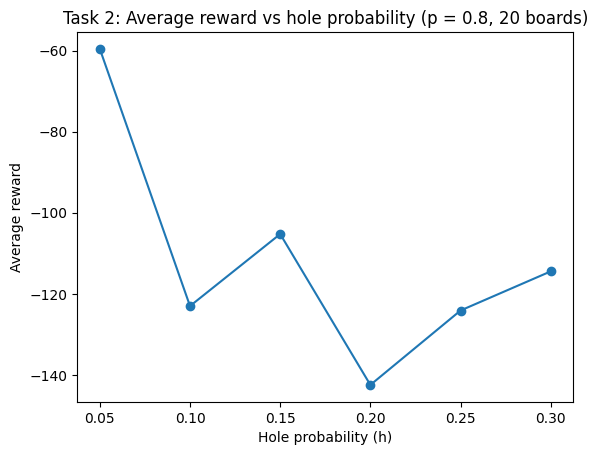

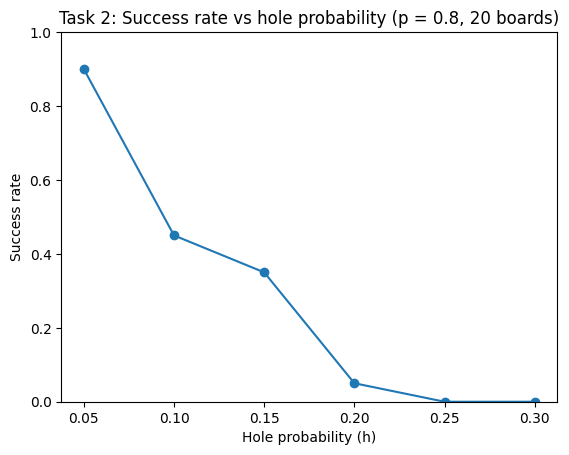

In [5]:
import matplotlib.pyplot as plt

# Task 2: average reward as the hole chance goes up
plt.plot(h_values, avg_rewards_h, marker="o")
plt.xlabel("Hole probability (h)")
plt.ylabel("Average reward")
plt.title("Task 2: Average reward vs hole probability (p = 0.8, 20 boards)")
plt.show()

# Task 2: success rate as the hole chance goes up
plt.plot(h_values, success_rates_h, marker="o")
plt.xlabel("Hole probability (h)")
plt.ylabel("Success rate")
plt.ylim(0, 1)
plt.title("Task 2: Success rate vs hole probability (p = 0.8, 20 boards)")
plt.show()

In [6]:
## Task 3: varying action success probability p
h = 0.05
p_values = []
avg_rewards_p = []
success_rates_p = []

for p in [0.9, 0.8, 0.7, 0.6, 0.5]:
    outcomes = []
    totals = []
    golds = []
    for seed in range(1, 21):
        env = FrozenTreasureWorld(size=20, hole_prob=h, p=p, seed=seed)
        total, outcome = run_episode(env, h)
        outcomes.append(outcome)
        totals.append(total)
        golds.append(env.has_gold)
        print(p, seed, outcome, flush=True)
    avg = sum(totals) / len(totals)
    p_values.append(p)
    avg_rewards_p.append(avg)
    success_rates_p.append(outcomes.count("success") / 20)
    print("p =", p)
    print(Counter(outcomes))
    print("average reward:", avg)
    summarise(totals, outcomes, golds)

0.9 1 success
0.9 2 success
0.9 3 success
0.9 4 success
0.9 5 hole (slip)
0.9 6 success
0.9 7 success
0.9 8 success
0.9 9 success
0.9 10 success
0.9 11 hole (gamble)
0.9 12 success
0.9 13 success
0.9 14 success
0.9 15 hole (gamble)
0.9 16 success
0.9 17 success
0.9 18 success
0.9 19 success
0.9 20 success
p = 0.9
Counter({'success': 17, 'hole (gamble)': 2, 'hole (slip)': 1})
average reward: -75.05
std of reward: 144.4
average steps (successes): 315.2
average steps (deaths): 30.7
0.8 1 success
0.8 2 success
0.8 3 success
0.8 4 success
0.8 5 success
0.8 6 success
0.8 7 success
0.8 8 success
0.8 9 success
0.8 10 success
0.8 11 hole (gamble)
0.8 12 success
0.8 13 success
0.8 14 success
0.8 15 hole (gamble)
0.8 16 success
0.8 17 success
0.8 18 success
0.8 19 success
0.8 20 success
p = 0.8
Counter({'success': 18, 'hole (gamble)': 2})
average reward: -59.6
std of reward: 155.1
average steps (successes): 303.8
average steps (deaths): 11.5
0.7 1 success
0.7 2 success
0.7 3 success
0.7 4 success

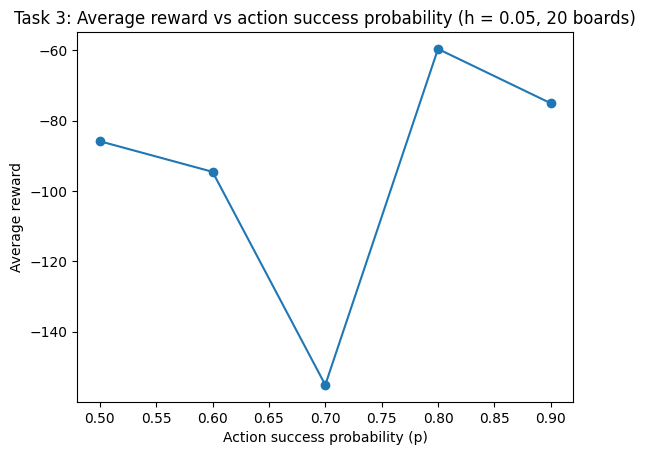

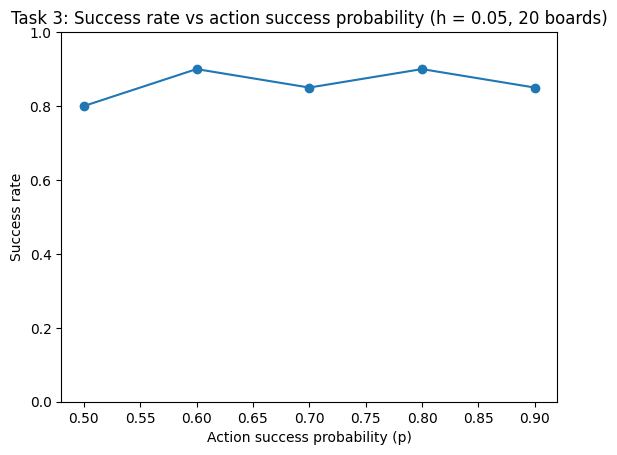

In [7]:
# Task 3: average reward as the ice gets more slippery
plt.plot(p_values, avg_rewards_p, marker="o")
plt.xlabel("Action success probability (p)")
plt.ylabel("Average reward")
plt.title("Task 3: Average reward vs action success probability (h = 0.05, 20 boards)")
plt.show()

# Task 3: success rate as the ice gets more slippery
plt.plot(p_values, success_rates_p, marker="o")
plt.xlabel("Action success probability (p)")
plt.ylabel("Success rate")
plt.ylim(0, 1)
plt.title("Task 3: Success rate vs action success probability (h = 0.05, 20 boards)")
plt.show()

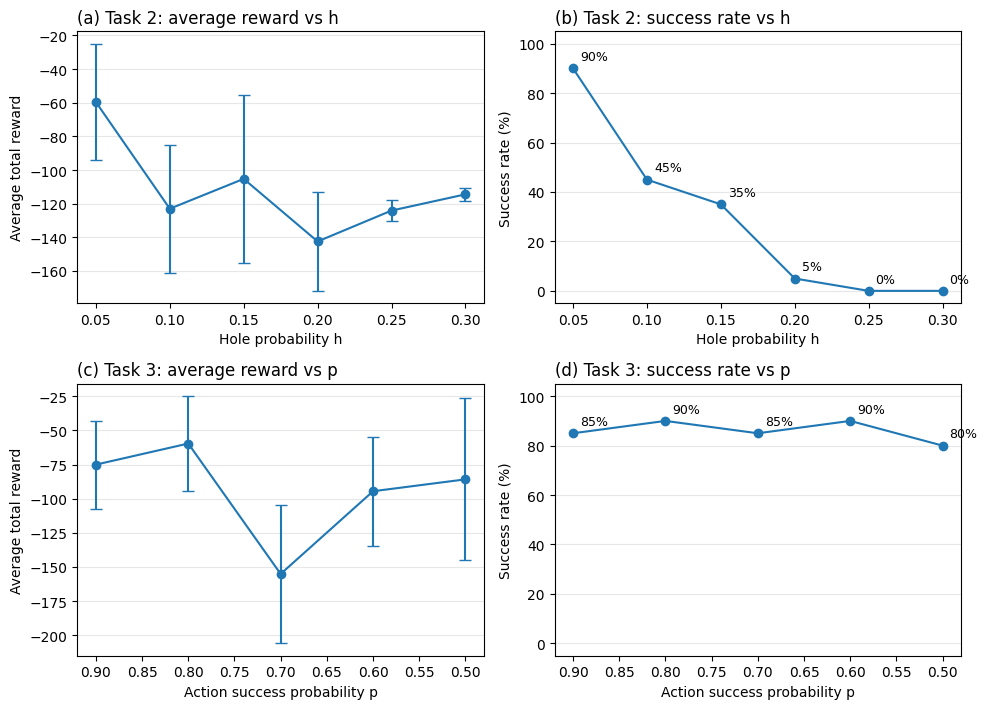

In [9]:
import math
import matplotlib.pyplot as plt

# Figure 1 in the report. Values copied from the Task 2 and Task 3 outputs above
h_list = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
h_avg  = [-59.6, -123.0, -105.25, -142.45, -124.1, -114.45]
h_std  = [155.1, 170.2, 223.4, 131.3, 28.8, 17.8]
h_succ = [90, 45, 35, 5, 0, 0]

p_list = [0.9, 0.8, 0.7, 0.6, 0.5]
p_avg  = [-75.05, -59.6, -155.15, -94.55, -85.85]
p_std  = [144.4, 155.1, 227.4, 179.3, 265.8]
p_succ = [85, 90, 85, 90, 80]

# error bars are the standard error: std / sqrt(20), since each setting has 20 lakes
def standard_error(stds):
    return [s / math.sqrt(20) for s in stds]

# writes the percentage next to each point on a success-rate plot
def label_points(a, xs, ys):
    for x, y in zip(xs, ys):
        a.annotate(f"{y}%", (x, y), textcoords="offset points", xytext=(5, 6), fontsize=9)

fig, ax = plt.subplots(2, 2, figsize=(10, 7.2))

ax[0][0].errorbar(h_list, h_avg, yerr=standard_error(h_std), marker="o", capsize=4)
ax[0][0].set_title("(a) Task 2: average reward vs h", loc="left")
ax[0][0].set_xlabel("Hole probability h")
ax[0][0].set_ylabel("Average total reward")

ax[0][1].plot(h_list, h_succ, marker="o")
label_points(ax[0][1], h_list, h_succ)
ax[0][1].set_title("(b) Task 2: success rate vs h", loc="left")
ax[0][1].set_xlabel("Hole probability h")
ax[0][1].set_ylabel("Success rate (%)")
ax[0][1].set_ylim(-5, 105)

ax[1][0].errorbar(p_list, p_avg, yerr=standard_error(p_std), marker="o", capsize=4)
ax[1][0].set_title("(c) Task 3: average reward vs p", loc="left")
ax[1][0].set_xlabel("Action success probability p")
ax[1][0].set_ylabel("Average total reward")
ax[1][0].invert_xaxis()   # more slippery to the right

ax[1][1].plot(p_list, p_succ, marker="o")
label_points(ax[1][1], p_list, p_succ)
ax[1][1].set_title("(d) Task 3: success rate vs p", loc="left")
ax[1][1].set_xlabel("Action success probability p")
ax[1][1].set_ylabel("Success rate (%)")
ax[1][1].set_ylim(-5, 105)
ax[1][1].invert_xaxis()

for a in ax.flat:
    a.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# ------------------------------------------------------
# Optional speed test: warm-start value iteration (Section 5.5)
# ------------------------------------------------------
# Not needed for the main results. It reruns the Task 1 lakes twice (about 9 minutes).
# The idea: each step the lake knowledge barely changes, so instead of starting
# value iteration from zeros, it starts from the previous step's values and needs far fewer passes.

# same as value_iteration, but starts from V_start (last step's values) when it is given
def value_iteration_warm(q, p, size, goals, V_start=None):
    V = {}
    for r in range(size):
        for c in range(size):
            if V_start is None:
                V[(r, c)] = 0
            else:
                V[(r, c)] = V_start[(r, c)]
    for g in goals:
        V[g] = goals[g]

    while True:
        new_V, policy = one_pass(V, q, p, size, goals)
        biggest = 0
        for s in V:
            change = abs(new_V[s] - V[s])
            biggest = max(biggest, change)
        V = new_V
        if biggest < 0.01:
            break

    return V, policy

# same as run_episode, but with a switch: warm=True passes last step's values into the planner
def run_episode_warm(env, h, max_steps=1000, warm=False):
    labels, visited, breezy = init_notebook(env.size)
    total = 0
    V = None   # no previous values yet
    for t in range(max_steps):
        percept = env.percept(*env.pos)
        update(env.pos, percept, labels, visited, breezy, env.neighbours)
        q = compute_q(labels, breezy, h, env.neighbours)
        if env.has_gold:
            goals = {(0, 0): 200}
            gambling = False
        else:
            goals, gambling = explore_goals(labels, visited, env.size)
        if warm:
            V, policy = value_iteration_warm(q, env.p, env.size, goals, V)
        else:
            V, policy = value_iteration_warm(q, env.p, env.size, goals)
        action = policy[env.pos]
        position, reward, done = env.step(action)
        total += reward
        if done:
            break
    if done and reward == 199:
        outcome = "success"
    elif done:
        if gambling:
            outcome = "hole (gamble)"
        else:
            outcome = "hole (slip)"
    else:
        outcome = "timeout"
    return total, outcome

# timing test: the normal planner vs the warm-start version on the Task 1 lakes
import time
for warm in [False, True]:
    start = time.time()
    outcomes = []
    totals = []
    for seed in range(1, 21):
        env = FrozenTreasureWorld(size=20, hole_prob=0.05, p=0.8, seed=seed)
        total, outcome = run_episode_warm(env, 0.05, warm=warm)
        outcomes.append(outcome)
        totals.append(total)
    print("warm start:", warm, "| time:", round(time.time() - start), "s",
          "| successes:", outcomes.count("success"), "| average reward:", sum(totals) / 20)

warm start: False | time: 622 s | successes: 18 | average reward: -59.6
warm start: True | time: 203 s | successes: 18 | average reward: -55.95
